In [3]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\DELL\Documents\Veda_Task42_Ecommerce_RFM
['.ipynb_checkpoints', 'Online Retail.xlsx', 'Untitled.ipynb']


In [4]:
import pandas as pd
from pathlib import Path

file_path = Path(r"C:\Users\DELL\Documents\Veda_Task42_Ecommerce_RFM\Online Retail.xlsx")

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (541909, 8)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [5]:
# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Remove duplicate rows
df = df.drop_duplicates()

# 4. Remove rows with missing CustomerID or Description
df = df.dropna(subset=["CustomerID", "Description"])

# 5. Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# 6. Remove invalid quantity and price
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# 7. Create TotalAmount column
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("\nCleaned dataset shape:", df.shape)
display(df.head())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Cleaned dataset shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [6]:
import pandas as pd

# Reference date: one day after the last transaction
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

print("RFM Analysis completed!")
print("Number of customers:", rfm.shape[0])
display(rfm.head(10))

RFM Analysis completed!
Number of customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


In [7]:
# Assign scores from 1 to 5
# Recency: lower days = better score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher purchases = better score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending = better score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Segment customers
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] >= 4:
        return "Recent Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    else:
        return "Needs Attention"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print("Customer segmentation completed!")
display(rfm.head(10))
print("\nSegment counts:")
display(rfm["Segment"].value_counts())

Customer segmentation completed!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,1,77183.60,1,1,5,115,Needs Attention
1,12347.0,2,7,4310.00,5,5,5,555,Champions
2,12348.0,75,4,1797.24,2,4,4,244,At Risk
3,12349.0,19,1,1757.55,4,1,4,414,Recent Customers
4,12350.0,310,1,334.40,1,1,2,112,Needs Attention
5,12352.0,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353.0,204,1,89.00,1,1,1,111,Needs Attention
7,12354.0,232,1,1079.40,1,1,4,114,Needs Attention
8,12355.0,214,1,459.40,1,1,2,112,Needs Attention
9,12356.0,23,3,2811.43,4,3,5,435,Loyal Customers



Segment counts:


Segment
Needs Attention     1425
Loyal Customers     1000
Champions            942
At Risk              661
Recent Customers     310
Name: count, dtype: int64

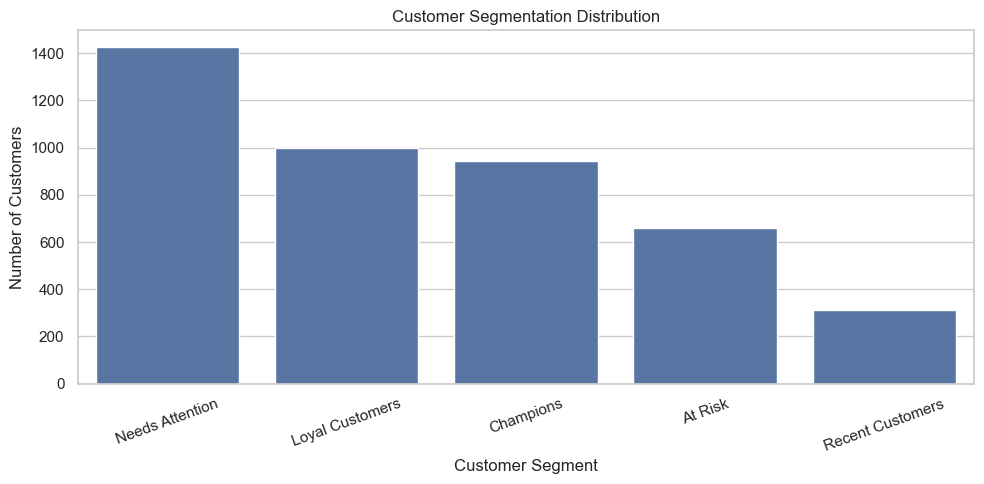

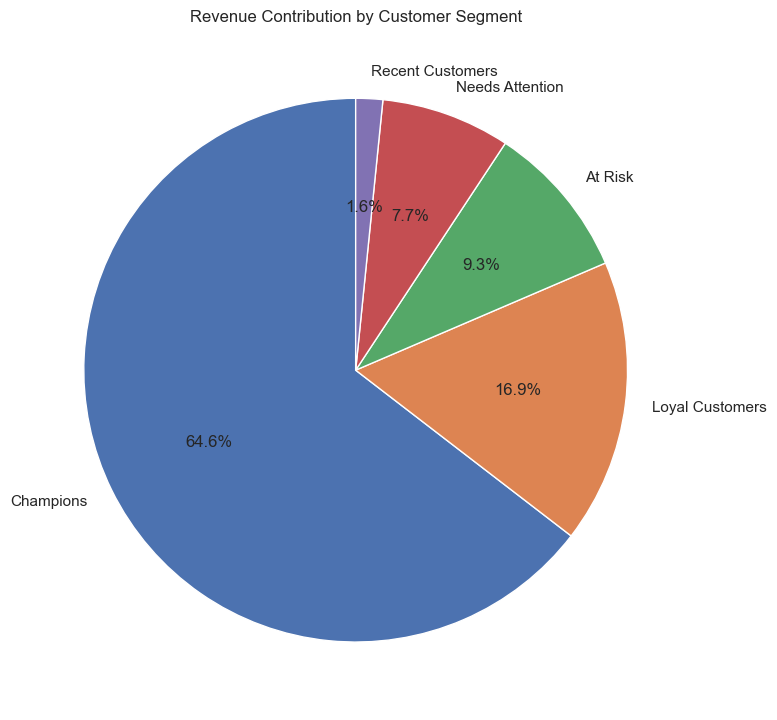

,Customers,Average_Recency,Average_Frequency,Total_Revenue
Segment,,,,
Needs Attention,1425,176.24,1.12,682410.56
Loyal Customers,1000,33.32,3.75,1500694.33
Champions,942,12.50,11.20,5737952.12
At Risk,661,150.64,3.41,823912.44
Recent Customers,310,18.10,1.25,142239.44


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Customer count by segment
segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)
plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 2. Revenue contribution by segment
revenue_by_segment = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 8))
plt.pie(
    revenue_by_segment.values,
    labels=revenue_by_segment.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue Contribution by Customer Segment")
plt.tight_layout()
plt.show()

# 3. Summary table
summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(summary.sort_values("Customers", ascending=False))

In [9]:
# Export RFM customer segmentation
rfm.to_csv("RFM_Customer_Segmentation.csv", index=False)

# Export segment summary
summary.to_csv("RFM_Segment_Summary.csv")

print("Files saved successfully!")

Files saved successfully!
